# Semana 13 — Redes neurais em manutenção preditiva: escolha, preparo e avaliação

Este notebook é um laboratório guiado com explicações detalhadas, gráficos e células progressivas. Vamos começar com uma revisão curta da MLP da Semana 12, analisar um dataset público de manutenção, construir um classificador tabular com baseline e, depois, preparar uma série temporal pública para discutir CNN 1D, LSTM e autoencoders.

**Pergunta FactoryHub:** como transformar sinais de sensores em uma informação útil para priorizar inspeções, sem confundir um score estatístico com diagnóstico de falha?

## Objetivos de aprendizagem

- reconhecer quando a pergunta pede classificação, regressão ou detecção de anomalias;
- preparar variáveis sem incluir identificadores ou informações do futuro;
- treinar e avaliar uma MLP comparada com baseline;
- construir janelas temporais sem embaralhar a ordem;
- justificar MLP, CNN 1D, LSTM ou autoencoder pelo tipo de dado e pelo uso operacional.

## Como a rede neural se encaixa nas fases do CRISP-DM

O **CRISP-DM tem seis fases**. A rede neural é uma técnica de modelagem dentro do processo, não uma fase do CRISP-DM.

| Fase do CRISP-DM | Aplicação neste estudo |
|---|---|
| 1. Entendimento do negócio | definir decisão de manutenção, alvo, usuário e custo dos erros |
| 2. Entendimento dos dados | conhecer datasets, colunas, distribuições e limitações |
| 3. Preparação dos dados | selecionar entradas, evitar vazamento, criar atributos e partições |
| 4. Modelagem | construir pipeline e **treinar a MLP**; comparar com Random Forest ou CNN temporal |
| 5. Avaliação | escolher limiar na validação, medir no teste e decidir se atende ao objetivo |
| 6. Implantação | documentar, disponibilizar saída ao FactoryHub e acompanhar o modelo |

Dentro das fases 3, 4 e 5 há **passos de aprendizado de máquina**: preparar X/y, separar dados, ajustar transformações, treinar, comparar, selecionar limiar e medir. Esses passos não são fases adicionais do CRISP-DM. O ciclo é iterativo: uma avaliação ruim pode levar de volta à compreensão dos dados ou à preparação.

## Revisão da Semana 12 — MLP e CRISP-DM

Responda antes de seguir:

1. Qual é a diferença entre classificar falha/sem falha e estimar temperatura futura?
2. Para que separar treino, validação e teste?
3. O que é vazamento quando uma variável só existe depois da falha?
4. Por que comparar a MLP com um modelo de referência?

**Síntese:** classificação estima classe; regressão estima valor contínuo. Treino ajusta parâmetros, validação escolhe configuração/limiar e teste estima desempenho final. Usar informação posterior é vazamento. O baseline mostra se a complexidade extra agrega valor.


## Dois datasets públicos, duas situações de aprendizagem

| Dataset | Origem e tipo | Bom para | Limite didático |
|---|---|---|---|
| AI4I 2020 Predictive Maintenance | UCI; 10 mil registros sintéticos de processo | classificação tabular e pipeline MLP | não representa todos os desafios de uma planta real; as linhas não formam uma série temporal confiável |
| MetroPT-3 | cópia pública no Kaggle, baixada via KaggleHub; telemetria temporal de compressor ferroviário | janelamento, previsão de sinal e discussão de anomalias sequenciais | arquivo grande e sem rótulo de falha em cada linha; requer contexto de eventos e divisão temporal |

Vamos executar o estudo supervisionado no AI4I e usar o MetroPT-3 para preparar uma série multissensor. As métricas não serão comparadas diretamente, pois os datasets têm tarefas e rótulos diferentes.

## Passo 0 — Ambiente e reprodutibilidade

O código usa Python, pandas, NumPy e scikit-learn. `ucimlrepo` baixa os dados diretamente do UCI; a primeira execução precisa de internet. Se estiver em ambiente sem acesso à internet, baixe o CSV na página oficial e carregue-o localmente.

In [20]:
# Se necessário, execute uma vez no terminal ou descomente no notebook:
# %pip install ucimlrepo pandas numpy scikit-learn matplotlib kagglehub
!pip install ucimlrepo

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

SEED = 42
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

## Fase 1 do CRISP-DM — Entendimento do negócio

**Decisão proposta:** priorizar uma inspeção quando as condições observadas se parecem com registros associados a falha no AI4I.

- **Unidade de previsão:** um registro de processo.
- **Alvo:** `Machine failure` (0 ou 1).
- **Uso do resultado:** sinal de apoio à priorização, não desligamento automático.
- **Erro perigoso:** falso negativo pode deixar passar um evento; muitos falsos positivos sobrecarregam a manutenção.
- **Métrica de acompanhamento:** recall, precisão, F1/PR-AUC e quantidade de alertas.

É um exercício educacional com dados sintéticos. Não é um modelo pronto para operação industrial.

## Fase 2 do CRISP-DM ? Entendimento dos dados: inspe??o do AI4I

UCI identifica o dataset pelo número 601. Veja as dimensões, nomes de colunas, primeiras linhas e alvos antes de escolher variáveis. A página oficial descreve `Machine failure` e também os modos `TWF`, `HDF`, `PWF`, `OSF` e `RNF`.

In [21]:
ai4i = fetch_ucirepo(id=601)
X_bruto = ai4i.data.features.copy()
y_bruto = ai4i.data.targets.copy()

print("features:", X_bruto.shape)
print("targets:", y_bruto.shape)
print("colunas de entrada:", list(X_bruto.columns))
print("colunas de alvo:", list(y_bruto.columns))
display(X_bruto.head())
display(y_bruto.head())

features: (10000, 6)
targets: (10000, 6)
colunas de entrada: ['Type', 'Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear']
colunas de alvo: ['Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9


,Machine failure,TWF,HDF,PWF,OSF,RNF
0,0,0,0,0,0,0
1,0,0,0,0,0,0
2,0,0,0,0,0,0
3,0,0,0,0,0,0
4,0,0,0,0,0,0


### Como interpretar as colunas

`UID` e `Product ID` identificam registros/produtos; não são medições físicas para a previsão. Entradas candidatas incluem variante `Type`, temperatura do ar/processo, velocidade, torque e desgaste da ferramenta. `Machine failure` é o alvo. Os modos de falha são rótulos derivados do mesmo evento: não os inclua como entradas para prever `Machine failure`, pois isso revela a resposta.

## Fase 3 do CRISP-DM — Limpeza, alvo e prevenção de vazamento

As funções abaixo encontram nomes mesmo se a biblioteca devolver pequenas diferenças de formatação. Vamos selecionar somente entradas documentadas e excluir todos os alvos e IDs. Confira a lista impressa antes de prosseguir.

In [22]:
def normalizar_nome(nome):
    return re.sub(r"[^a-z0-9]", "", str(nome).lower())

def localizar(colunas, prefixo_normalizado):
    encontrados = [c for c in colunas if normalizar_nome(c).startswith(prefixo_normalizado)]
    if not encontrados:
        raise KeyError(f"Não encontrei coluna iniciada por {prefixo_normalizado!r}: {list(colunas)}")
    return encontrados[0]

col_alvo = localizar(y_bruto.columns, "machinefailure")
col_type = localizar(X_bruto.columns, "type")
col_air = localizar(X_bruto.columns, "airtemperature")
col_process = localizar(X_bruto.columns, "processtemperature")
col_rpm = localizar(X_bruto.columns, "rotationalspeed")
col_torque = localizar(X_bruto.columns, "torque")
col_wear = localizar(X_bruto.columns, "toolwear")

colunas_modelo = [col_type, col_air, col_process, col_rpm, col_torque, col_wear]
X = X_bruto[colunas_modelo].copy()
y = y_bruto[col_alvo].astype(int).copy()
print("Entradas escolhidas:", colunas_modelo)
print("Alvo:", col_alvo)
print("IDs e modos de falha ficaram fora de X.")
display(X.head())

Entradas escolhidas: ['Type', 'Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear']
Alvo: Machine failure
IDs e modos de falha ficaram fora de X.


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9


## Passo 4 — Exploração inicial

Verifique tipo, ausência, distribuição do alvo e proporção de falhas. Se a falha for rara, um modelo que sempre responde “sem falha” pode ter acurácia aparentemente alta e utilidade nula.

,tipo
Type,object
Air temperature,float64
Process temperature,float64
Rotational speed,int64
Torque,float64
Tool wear,int64


,ausentes
Type,0
Air temperature,0
Process temperature,0
Rotational speed,0
Torque,0
Tool wear,0


,registros
Machine failure,
sem falha,9661
falha,339


,percentual
Machine failure,
0,96.61
1,3.39


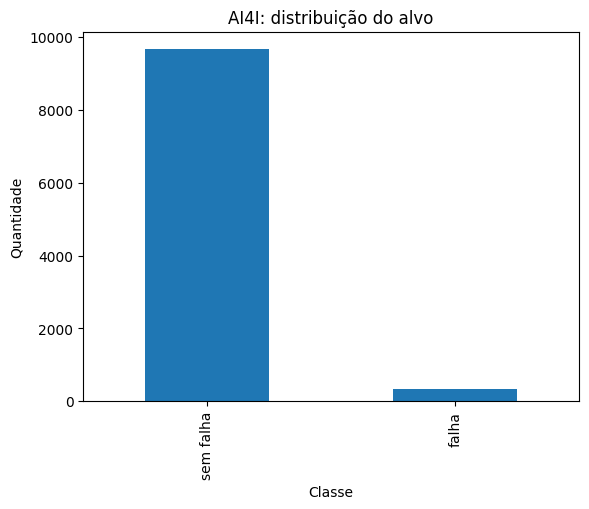

In [23]:
display(X.dtypes.to_frame("tipo"))
display(X.isna().sum().to_frame("ausentes"))
contagem = y.value_counts().sort_index().rename(index={0:"sem falha", 1:"falha"})
display(contagem.to_frame("registros"))
display((y.value_counts(normalize=True).sort_index()*100).rename("percentual").to_frame())

ax = contagem.plot(kind="bar", title="AI4I: distribuição do alvo")
ax.set_xlabel("Classe")
ax.set_ylabel("Quantidade")
plt.show()

### Visualização — distribuições dos sensores por classe

Compare a forma das distribuições, a sobreposição e a assimetria. Uma separação visual não prova causalidade, e sobreposição não significa que os sinais sejam inúteis: o padrão combinado pode conter informação. A densidade facilita comparar classes com contagens diferentes, mas não representa a prevalência real.

In [ ]:
sensores_plot = [col_air, col_process, col_rpm, col_torque, col_wear]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, coluna in zip(axes.flat, sensores_plot):
    ax.hist(X.loc[y == 0, coluna], bins=35, alpha=.6, density=True, label="Sem falha")
    ax.hist(X.loc[y == 1, coluna], bins=35, alpha=.6, density=True, label="Falha")
    ax.set_title(str(coluna)); ax.set_ylabel("Densidade"); ax.legend()
axes.flat[-1].axis("off")
fig.suptitle("AI4I — distribuição dos sinais por classe")
fig.tight_layout(); plt.show()

**Interpretação:** desbalanceamento muda como ler as métricas. Antes de escolher arquitetura, pergunte quantos alertas a equipe conseguiria verificar e qual tipo de erro tem maior custo.

## Passo 5 — Engenharia de atributos com justificativa

Podemos testar diferença entre temperatura de processo e ambiente e potência mecânica aproximada (`torque × velocidade angular`). São transformações calculáveis no instante da previsão. Não são leis completas da máquina; valide unidade, sensores e disponibilidade no cenário real.

In [24]:
# Nomes localizados na etapa anterior; a velocidade está em rpm.
delta_temp = X[col_process] - X[col_air]
potencia_aprox_w = X[col_torque] * (X[col_rpm] * 2 * np.pi / 60)
X["delta_temp_K"] = delta_temp
X["potencia_aprox_W"] = potencia_aprox_w
display(X[["delta_temp_K", "potencia_aprox_W"]].describe())

,delta_temp_K,potencia_aprox_W
count,10000.000000,10000.000000
mean,10.000630,6279.744953
std,1.001094,1067.418295
min,7.600000,1148.440610
25%,9.300000,5561.184484
50%,9.800000,6271.027344
75%,11.000000,7003.002724
max,12.100000,10469.923005


### Visualização — combinações de sinais

O gráfico de dispersão revela relações que uma inspeção univariada não mostra. A cor indica o alvo conhecido apenas para análise. Em aplicação real, o alvo não está disponível no instante da previsão. As faixas sobrepostas lembram que uma única regra simples não substitui o modelo nem o conhecimento de processo.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for classe, rotulo, cor in [(0, "Sem falha", "steelblue"), (1, "Falha", "crimson")]:
    m = (y == classe)
    axes[0].scatter(X.loc[m, col_rpm], X.loc[m, col_torque], s=12, alpha=.4, c=cor, label=rotulo)
    axes[1].scatter(X.loc[m, "delta_temp_K"], X.loc[m, "potencia_aprox_W"], s=12, alpha=.4, c=cor, label=rotulo)
axes[0].set(xlabel="Velocidade (rpm)", ylabel="Torque (Nm)", title="Sensores observados")
axes[1].set(xlabel="Diferença de temperatura (K)", ylabel="Potência aproximada (W)", title="Atributos derivados")
for ax in axes: ax.legend()
fig.tight_layout(); plt.show()

## Passo 6 — Divisão treino, validação e teste

O AI4I é sintético e não fornece uma sequência temporal real por máquina. Para este exemplo tabular, faremos divisões estratificadas aleatórias e fixaremos a semente. Em telemetria temporal, prefira corte cronológico ou por equipamento; nunca misture janelas vizinhas aleatoriamente entre treino e teste.

In [25]:
from sklearn.model_selection import train_test_split

X_treino_val, X_teste, y_treino_val, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
X_treino, X_validacao, y_treino, y_validacao = train_test_split(
    X_treino_val, y_treino_val, test_size=0.25, random_state=SEED, stratify=y_treino_val
)
print("treino:", X_treino.shape, "validação:", X_validacao.shape, "teste:", X_teste.shape)
print("taxa de falha:", round(y_treino.mean(), 4), round(y_validacao.mean(), 4), round(y_teste.mean(), 4))

treino: (6000, 8) validação: (2000, 8) teste: (2000, 8)
taxa de falha: 0.0338 0.034 0.034


## Fase 4 do CRISP-DM — Pipeline que evita vazamento de transformação

`OneHotEncoder` transforma `Type`; `StandardScaler` ajusta escala numérica. Ambos ficam dentro do `Pipeline`, portanto aprendem parâmetros apenas no treino durante `fit`. A MLP usa camadas ocultas `(32, 16)` como ponto de partida, não como arquitetura universal.

**Localização da rede neural:** a MLP é o modelo escolhido na Fase 4 (Modelagem). O pipeline prepara os dados e `fit` estima os pesos usando somente o treino. Ajustar hiperparâmetros e comparar modelos é trabalho de modelagem; decidir se o resultado atende ao objetivo pertence à Fase 5 (Avaliação).

### A MLP dentro da Fase 4 — Modelagem

A MLP (*Multilayer Perceptron*) é uma técnica escolhida para modelar a relação entre as entradas e `Machine failure`. Cada neurônio calcula uma soma ponderada dos valores recebidos, adiciona um viés e aplica uma função de ativação. As camadas ocultas `(32, 16)` aprendem combinações progressivamente mais abstratas; a camada de saída produz uma probabilidade para cada classe.

No `fit`, o modelo executa propagação direta para gerar previsões, mede uma função de perda, calcula como cada peso contribuiu para o erro (backpropagation) e atualiza os pesos pelo otimizador. Esse ciclo se repete em lotes e iterações. `alpha` regulariza pesos; `early_stopping` encerra quando uma validação interna deixa de melhorar. Mais camadas não garantem melhor desempenho.

Esse treinamento de pesos acontece na **Fase 4 do CRISP-DM, Modelagem**. O trabalho de dividir os dados e ajustar transformações pertence à preparação; comparar métricas e decidir se o modelo atende ao objetivo pertence à avaliação.

### Por que escalar e codificar?

Temperatura, velocidade, torque e desgaste têm unidades e amplitudes diferentes. Sem padronização, uma variável de grande escala pode dominar as atualizações. `StandardScaler` transforma os valores com média e desvio padrão aprendidos no treino. Como está dentro do `Pipeline`, essas estatísticas não são calculadas a partir de validação/teste.

`Type` contém categorias L, M e H. `OneHotEncoder` representa cada categoria sem inventar uma ordem numérica (como L < M < H). Essas operações tornam as entradas adequadas à MLP; elas não são camadas de uma nova fase do CRISP-DM.

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier

col_categorica = [col_type]
col_numericas = [c for c in X.columns if c not in col_categorica]
preparo = ColumnTransformer([
    ("categorica", OneHotEncoder(handle_unknown="ignore"), col_categorica),
    ("numerica", StandardScaler(), col_numericas),
])

mlp = Pipeline([
    ("preparo", preparo),
    ("modelo", MLPClassifier(
        hidden_layer_sizes=(32, 16), activation="relu", solver="adam",
        alpha=0.001, max_iter=400, early_stopping=True, random_state=SEED
    )),
])
mlp.fit(X_treino, y_treino)

Pipeline(steps=[('preparo',
                 ColumnTransformer(transformers=[('categorica',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type']),
                                                 ('numerica', StandardScaler(),
                                                  ['Air temperature',
                                                   'Process temperature',
                                                   'Rotational speed', 'Torque',
                                                   'Tool wear', 'delta_temp_K',
                                                   'potencia_aprox_W'])])),
                ('modelo',
                 MLPClassifier(alpha=0.001, early_stopping=True,
                               hidden_layer_sizes=(32, 16), max_iter=400,
                               random_state=42))])

### Visualização — curva de perda

A curva ajuda a inspecionar a otimização: redução da perda indica que o modelo está ajustando o treino; uma curva que estabiliza pode indicar convergência. Isso, sozinho, não mede generalização. `early_stopping` monitora uma fração interna do treino, enquanto a validação externa e o teste permanecem separados para nossas decisões e avaliação.

In [ ]:
loss = mlp.named_steps["modelo"].loss_curve_
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(loss)+1), loss, marker=".", linewidth=1)
plt.xlabel("Iteração"); plt.ylabel("Perda logarítmica")
plt.title("MLP — perda durante o ajuste no treino"); plt.grid(alpha=.25)
plt.show()

Se o treinamento exibir aviso de convergência, não aumente camadas às cegas: confira escala, separação, taxa de aprendizado, número de iterações e baseline. `early_stopping` usa parte do treino para monitorar ajuste; o conjunto de teste continua intocado.

## Passo 8 — Baseline e métricas

Compare com Random Forest usando o mesmo preparo e partições. Reporte recall, precisão, F1, average precision (aproximação da área sob a curva precisão-recall) e matriz de confusão. Acurácia isolada não responde se a máquina com falha foi detectada.

In [27]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             average_precision_score, balanced_accuracy_score)

baseline = Pipeline([
    ("preparo", preparo),
    ("modelo", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                      random_state=SEED, n_jobs=-1)),
])
baseline.fit(X_treino, y_treino)

for nome, modelo in [("MLP", mlp), ("Random Forest", baseline)]:
    pred = modelo.predict(X_validacao)
    prob = modelo.predict_proba(X_validacao)[:, 1]
    print("\n", nome)
    print("balanced accuracy:", round(balanced_accuracy_score(y_validacao, pred), 3))
    print("average precision:", round(average_precision_score(y_validacao, prob), 3))
    print(classification_report(y_validacao, pred, zero_division=0))
    print("matriz de confusão [linhas=real, colunas=previsto]:\n", confusion_matrix(y_validacao, pred))


 MLP
balanced accuracy: 0.558
average precision: 0.37
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1932
           1       0.80      0.12      0.21        68

    accuracy                           0.97      2000
   macro avg       0.88      0.56      0.59      2000
weighted avg       0.96      0.97      0.96      2000

matriz de confusão [linhas=real, colunas=previsto]:
 [[1930    2]
 [  60    8]]

 Random Forest
balanced accuracy: 0.801
average precision: 0.844
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1932
           1       0.98      0.60      0.75        68

    accuracy                           0.99      2000
   macro avg       0.98      0.80      0.87      2000
weighted avg       0.99      0.99      0.98      2000

matriz de confusão [linhas=real, colunas=previsto]:
 [[1931    1]
 [  27   41]]


### Visualização — precisão-recall e matriz de confusão

A curva precisão-recall mostra como muda a precisão quando tentamos capturar mais falhas. A matriz abaixo usa limiar 0,5 e conta casos reais versus previstos. O canto inferior esquerdo (falha classificada como sem falha) representa eventos que poderiam escapar; o superior direito mostra falsos alarmes. Avalie o custo de ambos com o processo de manutenção.

In [ ]:
from sklearn.metrics import precision_recall_curve, ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for nome, modelo, cor in [("MLP", mlp, "darkorange"), ("Random Forest", baseline, "teal")]:
    prob = modelo.predict_proba(X_validacao)[:, 1]
    pr, rc, _ = precision_recall_curve(y_validacao, prob)
    axes[0].plot(rc, pr, label=nome, color=cor)
axes[0].set(xlabel="Recall", ylabel="Precisão", title="Validação: precisão-recall")
axes[0].set(xlim=(0,1), ylim=(0,1.02)); axes[0].grid(alpha=.25); axes[0].legend()
ConfusionMatrixDisplay.from_predictions(y_validacao, mlp.predict(X_validacao),
    display_labels=["Sem falha", "Falha"], cmap="Blues", colorbar=False, ax=axes[1])
axes[1].set_title("MLP, limiar 0,5 — validação")
fig.tight_layout(); plt.show()

### Como ler os resultados

- **Recall da falha:** fração das falhas detectadas; baixo recall significa eventos perdidos.
- **Precisão da falha:** fração dos alertas que eram falhas; baixa precisão gera inspeções desnecessárias.
- **Average precision:** resume a curva precisão-recall, útil quando a classe positiva é rara; compare sempre na mesma partição.
- **Balanced accuracy:** média do recall por classe, para não premiar apenas a classe majoritária.

O melhor modelo depende da capacidade de manutenção e do custo de cada erro.

## Fase 5 do CRISP-DM — Limiar de decisão escolhido na validação

`predict()` costuma usar limiar padrão 0,5. Em manutenção, o ponto adequado pode ser outro. Vamos escolher um limiar que maximize F2 na validação (dando mais peso ao recall) e só depois avaliar uma única vez no teste. Essa escolha é didática; um projeto real deveria incluir custo/capacidade e validação temporal.

In [28]:
from sklearn.metrics import precision_recall_curve, fbeta_score

prob_validacao = mlp.predict_proba(X_validacao)[:, 1]
prec, rec, limiares = precision_recall_curve(y_validacao, prob_validacao)
f2 = (5 * prec[:-1] * rec[:-1]) / (4 * prec[:-1] + rec[:-1] + 1e-12)
limiar = limiares[int(np.argmax(f2))]
print("limiar escolhido na validação:", round(float(limiar), 3))
print("F2 na validação:", round(float(np.max(f2)), 3))

limiar escolhido na validação: 0.1
F2 na validação: 0.497


### Gr?fico ? efeito do limiar sobre precis?o e recall

Cada limiar transforma probabilidades em decis?es bin?rias. Ao baixar o corte, geralmente capturamos mais positivos (recall aumenta), mas podemos gerar mais falsos alarmes (precis?o pode cair). O ponto destacado foi escolhido na valida??o; nunca escolha o limiar usando o conjunto de teste.

In [ ]:
from sklearn.metrics import precision_score, recall_score
preds_por_limiar = [(prob_validacao >= t).astype(int) for t in limiares]
precisao_t = [precision_score(y_validacao, z, zero_division=0) for z in preds_por_limiar]
recall_t = [recall_score(y_validacao, z, zero_division=0) for z in preds_por_limiar]
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(limiares, precisao_t, label="Precis?o")
ax.plot(limiares, recall_t, label="Recall")
ax.axvline(limiar, color="black", linestyle="--", label=f"Limiar escolhido={limiar:.2f}")
ax.set(xlabel="Limiar de probabilidade", ylabel="M?trica", ylim=(0, 1.02), title="Compromisso entre falsos alarmes e falhas detectadas")
ax.grid(alpha=.25); ax.legend(); plt.show()

## Fase 5 do CRISP-DM — Avaliação final no teste

Não retreine nem ajuste o limiar após observar o resultado do teste nesta demonstração. Se o desempenho for fraco, volte ao ciclo de desenvolvimento e avalie em uma nova partição definida antes da comparação.

In [29]:
from sklearn.metrics import precision_score, recall_score, f1_score

prob_teste = mlp.predict_proba(X_teste)[:, 1]
pred_teste = (prob_teste >= limiar).astype(int)
print("limiar fixado:", round(float(limiar), 3))
print("precision:", round(precision_score(y_teste, pred_teste, zero_division=0), 3))
print("recall:", round(recall_score(y_teste, pred_teste, zero_division=0), 3))
print("F1:", round(f1_score(y_teste, pred_teste, zero_division=0), 3))
print("matriz de confusão:\n", confusion_matrix(y_teste, pred_teste))

limiar fixado: 0.1
precision: 0.268
recall: 0.662
F1: 0.381
matriz de confusão:
 [[1809  123]
 [  23   45]]


## Fase 6 do CRISP-DM — Implantação e comunicação responsável

Uma MLP não explica causalidade. Converta a saída em linguagem operacional com ressalvas: “o modelo atribuiu maior score a estes registros com base nos padrões do dataset sintético”. Não diga “a máquina vai falhar” nem use sozinho para decisão de segurança.

Documente dataset/versão, seleção de colunas, partição, limiar, métricas, limitações e responsável pelo acompanhamento.

## Segundo dataset público: MetroPT-3 para sequências

MetroPT-3 contém leituras multivariadas de sensores de compressor de uma unidade de produção de ar de trem e relatórios de eventos. Nesta aula, a cópia é baixada do Kaggle via KaggleHub. As leituras não trazem um rótulo simples de falha por linha: uma tarefa de anomalia exige alinhar eventos, janelas e contexto operacional. O CSV é grande; confira memória e espaço antes do download.

### Passo 12 — Carregar e inspecionar MetroPT-3

O bloco usa `kagglehub.dataset_download` com o handle configurado pela turma, lista os arquivos encontrados, seleciona o CSV principal e o lê com pandas. Em ambiente local, configure a autenticação Kaggle quando solicitada; no Kaggle Notebook, a biblioteca usa a integração do ambiente. Confira o nome do arquivo, dimensões e colunas antes de continuar.

In [30]:
import os
import pandas as pd
import kagglehub

# Baixa a versão mais recente dos arquivos do dataset do Kaggle
print("Baixando dataset do Kaggle...")
path = kagglehub.dataset_download("joebeachcapital/metropt-3-dataset")
print("Caminho dos arquivos baixados:", path)

# Lista todos os arquivos encontrados recursivamente para identificar a estrutura
arquivos_encontrados = []
for raiz, dirs, arquivos in os.walk(path):
    for arquivo in arquivos:
        arquivos_encontrados.append(os.path.join(raiz, arquivo))

print("\nArquivos disponíveis no diretório do dataset:")
for f in arquivos_encontrados:
    print(f)

# Filtra o arquivo principal (CSV grande que contém as métricas limpas ou brutas)
csvs = [f for f in arquivos_encontrados if f.endswith('.csv')]
if not csvs:
    raise FileNotFoundError("Nenhum arquivo .csv encontrado no diretório do dataset.")

# Seleciona o maior CSV ou o mais provável de conter os dados (normalmente o maior arquivo)
csv_path = max(csvs, key=os.path.getsize)
print(f"\nCarregando o maior CSV encontrado: {csv_path}")

# Carrega as features do sensor
metro_features = pd.read_csv(csv_path)

print("Dimensões do dataset:", metro_features.shape)
print("Colunas encontradas:", list(metro_features.columns))
display(metro_features.head())

Baixando dataset do Kaggle...
Using Colab cache for faster access to the 'metropt-3-dataset' dataset.
Caminho dos arquivos baixados: /kaggle/input/metropt-3-dataset

Arquivos disponíveis no diretório do dataset:
/kaggle/input/metropt-3-dataset/MetroPT3(AirCompressor).csv
/kaggle/input/metropt-3-dataset/Data Description_Metro.pdf

Carregando o maior CSV encontrado: /kaggle/input/metropt-3-dataset/MetroPT3(AirCompressor).csv
Dimensões do dataset: (1516948, 17)
Colunas encontradas: ['Unnamed: 0', 'timestamp', 'TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Motor_current', 'COMP', 'DV_eletric', 'Towers', 'MPG', 'LPS', 'Pressure_switch', 'Oil_level', 'Caudal_impulses']


,Unnamed: 0,timestamp,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
0,0,2020-02-01 00:00:00,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
1,10,2020-02-01 00:00:10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2,20,2020-02-01 00:00:19,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
3,30,2020-02-01 00:00:29,-0.012,9.328,9.312,-0.022,9.328,53.425,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
4,40,2020-02-01 00:00:39,-0.012,9.318,9.302,-0.022,9.318,53.475,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0


O dataset é temporal e operacional, mas não vem com rótulo binário por linha. UCI lista relatórios de eventos de falha e recomenda usar o primeiro mês para treino e o restante para teste. Logo, podemos preparar previsão de sinal/anomalia; para classificação supervisionada é necessário construir rótulos temporais a partir dos relatórios, com regra explícita e revisão de domínio.

### Passo 13 — Preparar uma série ordenada

O bloco abaixo localiza timestamp e sinais de exemplo. Use apenas colunas que existirem no arquivo. Para manter o exercício manejável, selecione um período contínuo, preserve a ordem e verifique o intervalo de amostragem observado em vez de assumir frequência.

In [31]:
def buscar_coluna(df, nome_normalizado):
    # Remove sublinhados e força minúsculas para um casamento de nomes perfeito
    mapa = {normalizar_nome(c).replace("_", ""): c for c in df.columns}
    nome_busca = nome_normalizado.lower().replace("_", "")
    if nome_busca not in mapa:
        raise KeyError(f"Coluna {nome_normalizado!r} ausente. Colunas mapeadas: {list(mapa.keys())}")
    return mapa[nome_busca]

col_ts = buscar_coluna(metro_features, "timestamp")
metro_df = metro_features.copy()
metro_df[col_ts] = pd.to_datetime(metro_df[col_ts], errors="coerce")
metro_df = metro_df.dropna(subset=[col_ts]).sort_values(col_ts)
print("período:", metro_df[col_ts].min(), "→", metro_df[col_ts].max())
print("diferenças entre leituras:")
display(metro_df[col_ts].diff().dropna().describe())

nomes_sensores = ["tp2", "tp3", "h1", "motor_current", "oil_temperature"]
col_sensores = [buscar_coluna(metro_df, n) for n in nomes_sensores]
metro_df[col_sensores] = metro_df[col_sensores].apply(pd.to_numeric, errors="coerce")
metro_df = metro_df.dropna(subset=col_sensores)
display(metro_df[[col_ts] + col_sensores].head())

período: 2020-02-01 00:00:00 → 2020-09-01 03:59:50
diferenças entre leituras:


,timestamp
count,1516947
mean,0 days 00:00:12.141221809
std,0 days 00:05:14.107266185
min,0 days 00:00:08
25%,0 days 00:00:10
50%,0 days 00:00:10
75%,0 days 00:00:10
max,2 days 00:01:58


,timestamp,TP2,TP3,H1,Motor_current,Oil_temperature
0,2020-02-01 00:00:00,-0.012,9.358,9.340,0.0400,53.600
1,2020-02-01 00:00:10,-0.014,9.348,9.332,0.0400,53.675
2,2020-02-01 00:00:19,-0.012,9.338,9.322,0.0425,53.600
3,2020-02-01 00:00:29,-0.012,9.328,9.312,0.0400,53.425
4,2020-02-01 00:00:39,-0.012,9.318,9.302,0.0400,53.475


### Visualização — série de pressão e corrente

O recorte temporal permite observar variação, estabilidade e mudanças de regime em dois canais. Uma mudança pode refletir estado operacional legítimo, não defeito. Consulte timestamps de eventos, contexto e definições dos sensores antes de rotular. O gráfico é exploratório; não é uma classificação automática.

In [ ]:
recorte = metro_df.iloc[:min(5000, len(metro_df))]
tp2 = buscar_coluna(metro_df, "tp2")
motor = buscar_coluna(metro_df, "motor_current")
fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.plot(recorte[col_ts], recorte[tp2], color="navy", linewidth=.8)
ax1.set(xlabel="Instante", ylabel="TP2 (pressão)", title="MetroPT-3 — recorte cronológico do compressor")
ax1.grid(alpha=.2)
ax2 = ax1.twinx(); ax2.plot(recorte[col_ts], recorte[motor], color="darkorange", alpha=.65, linewidth=.7)
ax2.set_ylabel("Corrente do motor")
fig.tight_layout(); plt.show()

### Contexto para leitura do MetroPT-3

O arquivo representa um equipamento em operação ao longo do tempo, por isso cada leitura depende do estado anterior e do regime de carga. Antes da modelagem, examine frequência real, períodos sem dados, mudanças de operação e manutenção. O identificador de linha não é um sensor. O timestamp ordena as observações e define o que era conhecido no momento da previsão.

### Passo 14 — Separação cronológica antes das janelas

Vamos demonstrar previsão do próximo valor de TP2 a partir de uma janela multissensor. O corte ocorre por data, nunca por embaralhamento. A escala é ajustada somente no trecho de treino. Para uma análise fiel ao protocolo do UCI, use um mês completo para treino e datas posteriores para teste; este código usa 80% cronológicos apenas como demonstração genérica.

In [32]:
# Corte cronológico para demonstração. Para relatório formal, use a recomendação mensal do UCI.
corte_tempo = metro_df[col_ts].iloc[int(len(metro_df) * 0.8)]
treino_temporal = metro_df[metro_df[col_ts] < corte_tempo].copy()
teste_temporal = metro_df[metro_df[col_ts] >= corte_tempo].copy()
print("corte:", corte_tempo)
print("linhas treino/teste:", len(treino_temporal), len(teste_temporal))

from sklearn.preprocessing import StandardScaler
escala = StandardScaler()
treino_scaled = escala.fit_transform(treino_temporal[col_sensores])
teste_scaled = escala.transform(teste_temporal[col_sensores])

corte: 2020-07-20 15:58:44
linhas treino/teste: 1213558 303390


### Visualização — separação passado/futuro

Uma divisão aleatória permitiria que pontos muito próximos fossem repartidos entre treino e teste e produziria uma avaliação otimista. O gráfico marca o instante de corte: treino fica antes, teste depois. Ajustamos a escala só no treino e aplicamos os mesmos parâmetros ao futuro.

In [ ]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(treino_temporal[col_ts], treino_temporal[tp2], label="Treino (passado)", linewidth=.7)
ax.plot(teste_temporal[col_ts], teste_temporal[tp2], label="Teste (futuro)", linewidth=.7)
ax.axvline(corte_tempo, color="black", linestyle="--", label="Corte temporal")
ax.set(title="MetroPT-3 — divisão cronológica", xlabel="Instante", ylabel="TP2")
ax.legend(); ax.grid(alpha=.2); fig.tight_layout(); plt.show()

### Passo 15 — Criar janelas com formato para CNN/LSTM

Cada amostra usa 60 observações passadas de 5 sensores para prever TP2 no passo seguinte. Criamos janelas separadamente dentro de treino e teste para nenhuma janela atravessar o corte.

In [33]:
def criar_janelas(matriz, indice_alvo, passos=60):
    X_seq, y_seq = [], []
    for fim in range(passos, len(matriz)):
        X_seq.append(matriz[fim-passos:fim, :])
        y_seq.append(matriz[fim, indice_alvo])
    return np.asarray(X_seq, dtype=np.float32), np.asarray(y_seq, dtype=np.float32)

idx_tp2 = col_sensores.index(buscar_coluna(metro_df, "tp2"))
X_seq_treino, y_seq_treino = criar_janelas(treino_scaled, idx_tp2, passos=60)
X_seq_teste, y_seq_teste = criar_janelas(teste_scaled, idx_tp2, passos=60)
print("forma treino:", X_seq_treino.shape, y_seq_treino.shape)
print("forma teste:", X_seq_teste.shape, y_seq_teste.shape)
# Esperado: (amostras, 60 passos, 5 canais)

forma treino: (1213498, 60, 5) (1213498,)
forma teste: (303330, 60, 5) (303330,)


### Visualização — como fica uma janela de entrada

Uma amostra tem 60 instantes × 5 sensores. A CNN/LSTM recebe apenas esse trecho passado; o alvo é o próximo valor de TP2. O gráfico mostra uma janela padronizada e destaca que o alvo está fora da entrada. Janela e alvo precisam respeitar equipamento, ordem temporal e fronteiras de manutenção.

In [ ]:
idx = min(10, len(X_seq_treino)-1)
janela = X_seq_treino[idx]
fig, axes = plt.subplots(len(col_sensores), 1, figsize=(11, 9), sharex=True)
for j, ax in enumerate(axes):
    ax.plot(np.arange(janela.shape[0]), janela[:, j], color="slateblue")
    ax.set_ylabel(str(col_sensores[j])); ax.grid(alpha=.2)
axes[-1].set_xlabel("Passos passados (valores padronizados)")
fig.suptitle("Janela multissensor → alvo TP2 no passo seguinte")
fig.tight_layout(); plt.show()
print("Alvo futuro de TP2 (padronizado):", y_seq_treino[idx])

## MLP, CNN 1D, LSTM ou autoencoder: decisão fundamentada

| Forma da entrada/pergunta | Candidato inicial | Comparação obrigatória |
|---|---|---|
| atributos agregados por registro/ciclo (AI4I) | MLP | baseline e Random Forest |
| sequências multissensor com padrões locais (MetroPT-3) | CNN 1D | último valor / estatísticas + modelo tabular |
| sequência longa com dependência temporal justificada | LSTM | CNN 1D e baseline temporal |
| dados normais abundantes, poucos rótulos | autoencoder exploratório | limites estatísticos e validação de eventos |

Autoencoder produz score de reconstrução, não causa. Em qualquer arquitetura, monitore deriva de sensores e versões do equipamento.

### O que a arquitetura vê

- **MLP:** um vetor de atributos por linha ou janela resumida; boa referência para o AI4I tabular.
- **CNN 1D:** filtros percorrem pontos vizinhos e aprendem formas locais, como uma subida de pressão dentro do ciclo.
- **LSTM:** processa a ordem passo a passo e mantém um estado resumido; pode ser útil para dependências temporais mais longas, com maior custo.
- **Autoencoder:** aprende reconstrução de padrões considerados normais; erro alto é um score para investigar, não uma causa confirmada.

O exercício MetroPT-3 de prever o próximo TP2 ensina formato de janela, não prova previsão de falha. Para classificar/analisar anomalias será preciso alinhar relatórios de falha com janelas, definir antecedência e estabelecer o que conta como alerta útil antes do ajuste.

## Fontes dos datasets e referências

- UCI. **AI4I 2020 Predictive Maintenance Dataset** (sintético; licença CC BY 4.0): <https://archive.ics.uci.edu/dataset/601/ai4i>. DOI: `10.24432/C5HS5C`.
- Kaggle, cópia usada no notebook: <https://www.kaggle.com/datasets/joebeachcapital/metropt-3-dataset>. Confirme versão/licença na página do dataset. KaggleHub: <https://github.com/Kaggle/kagglehub>. Dataset original e descrição: UCI <https://archive.ics.uci.edu/dataset/791/metropt+3+>, DOI `10.24432/C5VW3R`.
- Scikit-learn. **MLP para classificação supervisionada**: <https://scikit-learn.org/stable/modules/neural_networks_supervised.html>.
- TensorFlow. **Previsão de séries temporais**: <https://www.tensorflow.org/tutorials/structured_data/time_series>.
- Matzka, S. **Explainable Artificial Intelligence for Predictive Maintenance Applications** (AI4I, 2020).